In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# (Preprocessing & Feature Selection)
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

#Machine Learning Models
from sklearn.linear_model import LinearRegression

#Metrics
from sklearn.metrics import accuracy_score, confusion_matrix

from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
from sklearn.metrics import mean_squared_error as MSE

from sklearn.metrics import mean_squared_error, mean_absolute_error,  r2_score, mean_squared_log_error
from sklearn.linear_model import Ridge
from sklearn.linear_model import LassoCV,RidgeCV
from sklearn.linear_model import Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import AdaBoostRegressor
import warnings
warnings.filterwarnings('ignore')


In [2]:
trainData = pd.read_csv("Train_Set.csv")
trainData = trainData.loc[:, ~trainData.columns.str.contains('Unnamed')]

# Drop features (size, condition, paint_color,id, posting_date)

In [3]:
drop_columns = ['size', 'condition', 'paint_color', 'posting_date']

trainData = trainData.drop(columns = drop_columns)

In [4]:
missing_values = trainData.isna().sum(axis=1)

trainData = trainData.loc[missing_values <= 4]

In [5]:
trainData.reset_index(drop=True, inplace=True)

In [6]:
trainData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 289832 entries, 0 to 289831
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            289832 non-null  int64  
 1   year          289832 non-null  float64
 2   manufacturer  278696 non-null  object 
 3   model         289832 non-null  object 
 4   cylinders     170801 non-null  object 
 5   fuel          288480 non-null  object 
 6   odometer      289832 non-null  float64
 7   title_status  284862 non-null  object 
 8   transmission  289832 non-null  object 
 9   drive         202037 non-null  object 
 10  type          227448 non-null  object 
 11  state         289832 non-null  object 
 12  lat           285630 non-null  float64
 13  long          285630 non-null  float64
 14  price         289832 non-null  int64  
dtypes: float64(4), int64(2), object(9)
memory usage: 33.2+ MB


# Delete duplicates row 

In [7]:
trainData = trainData.drop_duplicates()

trainData.reset_index(drop=True, inplace=True)

# fill manufacturer by model

In [8]:
valid_manufacturers = trainData.dropna(subset=['manufacturer']).drop_duplicates(subset=['model'])
manufacturer_map = valid_manufacturers.set_index('model')['manufacturer'].to_dict()

trainData['manufacturer'] = trainData['manufacturer'].fillna(trainData['model'].map(manufacturer_map))

# fill null values with mode manufacturer

In [9]:
manufacturer_mode = trainData['manufacturer'].mode()[0]

trainData['manufacturer'].fillna(manufacturer_mode, inplace=True)

# Drop Outliers odometer

In [10]:
maxOdometer = trainData["odometer"].max()

In [11]:
trainData.drop(trainData[trainData["odometer"] == 0].index,inplace=True)
trainData.drop(trainData[trainData["odometer"] == maxOdometer].index,inplace=True)

In [12]:
sorted_odometer = sorted(trainData["odometer"])

In [13]:
odometer_lower_bound, odometer_upper_bound = np.percentile(sorted_odometer, [0.5, 99.9])

print(odometer_lower_bound, odometer_upper_bound)

2.0 1111111.0


In [14]:
trainData = trainData[(trainData['odometer'] <= odometer_upper_bound) & (trainData['odometer'] >= odometer_lower_bound)]

trainData.reset_index(drop=True, inplace=True)

# Drop Outliers price

In [15]:
max_price = trainData["price"].max()

In [16]:
sorted_price = sorted(trainData["price"])

In [17]:
price_lower_bound, price_upper_bound = np.percentile(sorted_price, [8, 99.9])

print(price_lower_bound, price_upper_bound)

158.0 114995.0


In [18]:
trainData = trainData[(trainData['price'] <= price_upper_bound) & (trainData['price'] >= price_lower_bound)]

In [19]:
trainData.reset_index(drop=True, inplace=True)

# fill drive depinding on model

In [20]:
drive_mode_map = trainData.dropna(subset=['drive']).groupby('model')['drive'].agg(lambda x: x.mode()[0] if not x.mode().empty else None).to_dict()

trainData['drive'] = trainData['drive'].fillna(trainData['model'].map(drive_mode_map))

In [21]:
trainData['drive'] = trainData['drive'].fillna(trainData['model'].map(drive_mode_map))

In [22]:
trainData["fuel"].value_counts(normalize=True) * 100


fuel
gas         84.396806
other        7.246708
diesel       6.658282
hybrid       1.283561
electric     0.414642
Name: proportion, dtype: float64

In [23]:
global_type = trainData['drive'].mode()[0]
trainData['drive'].fillna(global_type, inplace=True)

# fill cylinders depinding on model

In [24]:
model_cylinders_mode = trainData.dropna(subset=['cylinders']).groupby('model')['cylinders'].agg(lambda x: x.mode()[0] if not x.mode().empty else None).to_dict()

trainData['cylinders'] = trainData['cylinders'].fillna(trainData['model'].map(model_cylinders_mode))

global_cylinders = trainData['cylinders'].mode()[0]
trainData['cylinders'].fillna(global_cylinders, inplace=True)

# fill fuel with mode()

In [25]:
fuel_mode = trainData['fuel'].mode()[0]

trainData['fuel'].fillna(fuel_mode, inplace=True)

# fill title_status with mode()

In [26]:
title_mode = trainData['title_status'].mode()[0]

trainData['title_status'].fillna(title_mode, inplace=True)

# fill type depinding on model

In [27]:
valid_types = trainData.dropna(subset=['type']).drop_duplicates(subset=['model'])
type_map = valid_types.set_index('model')['type'].to_dict()

trainData['type'] = trainData['type'].fillna(trainData['model'].map(type_map))

global_type = trainData['type'].mode()[0]
trainData['type'].fillna(global_type, inplace=True)

# fill missing values from lat and long

In [28]:
trainData['lat'] = trainData['lat'].fillna(trainData.groupby('state')['lat'].transform('mean'))

trainData['long'] = trainData['long'].fillna(trainData.groupby('state')['long'].transform('mean'))

trainData['lat'] = trainData['lat'].fillna(trainData['lat'].mean())
trainData['long'] = trainData['long'].fillna(trainData['long'].mean())

In [29]:
trainData.isna().sum()

id              0
year            0
manufacturer    0
model           0
cylinders       0
fuel            0
odometer        0
title_status    0
transmission    0
drive           0
type            0
state           0
lat             0
long            0
price           0
dtype: int64

# Label Processing

In [30]:
label_encoder = preprocessing.LabelEncoder()

In [31]:
trainData[['manufacturer', 'model', 
       'cylinders', 'fuel', 'title_status', 'transmission',
       'drive', 'type',  'state']]=trainData[['manufacturer', 'model',
       'cylinders', 'fuel', 'title_status', 'transmission',
       'drive', 'type', 'state']].apply(label_encoder.fit_transform)


# Split Train and Test data

In [32]:
scaler = StandardScaler()

In [33]:
trainData['odometer'] = scaler.fit_transform(trainData['odometer'].to_numpy().reshape(-1, 1))
trainData['price'] = scaler.fit_transform(trainData['price'].to_numpy().reshape(-1, 1))

In [34]:
X = trainData.drop('price',axis=1)
y = trainData['price']

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [36]:
regressor = RandomForestRegressor(n_estimators=20, random_state=0)
regressor.fit(X_train, y_train)

RandomForestRegressor(n_estimators=20, random_state=0)

In [37]:
y_pred = regressor.predict(X_test)

In [38]:
print('Mean Absolute Error:', round(metrics.mean_absolute_error(y_test, y_pred),2))
print('Mean Squared Error:', round(metrics.mean_squared_error(y_test, y_pred),2))
print('Root Mean Squared Error:', round(np.sqrt(metrics.mean_squared_error(y_test, y_pred)),2))
print(metrics.r2_score(y_test , y_pred))

Mean Absolute Error: 0.17
Mean Squared Error: 0.13
Root Mean Squared Error: 0.36
0.8692802113048896


In [39]:
def result(y_test, y_pred):
    metrics_list=[]
    metrics_list.append('%.4f' % r2_score(y_test,y_pred))
    metrics_list.append('%.4f' % (r2_score(y_test,y_pred)*100))
    metrics_list.append('%.2f' % mean_squared_error(y_test, y_pred))
    metrics_list.append('%.2f' % mean_absolute_error(y_test, y_pred))
    metrics_list.append('%.2f' % np.sqrt(mean_squared_error(y_test, y_pred)))
    
    return (metrics_list)

#dataframe that store the performance of each model
score_data = pd.DataFrame(index=['R2 Score', 'Accuracy(%)', 'Mean Squared Error', 'Mean Absolute Error', 'Root MSE'])

In [40]:
LR = LinearRegression()
LR.fit(X_train, y_train)
y_pred = LR.predict(X_test)

In [41]:
R2_score = r2_score(y_test, y_pred)*100
score_lr = result(y_test, y_pred)
score_data['Linear Regression'] = score_lr
print('R2_score: ', score_lr[0])
print('Mean squared error: ', score_lr[2])
print('Mean absolute error: ', score_lr[3])
print('Root mean squared error: ', score_lr[4])

R2_score:  0.4419
Mean squared error:  0.55
Mean absolute error:  0.51
Root mean squared error:  0.74


In [42]:
RR = Ridge(alpha=20.336, solver='auto')
RR.fit(X_train, y_train)
y_pred = RR.predict(X_test)

In [43]:
score_rr = result(y_test, y_pred)
score_data['Ridge Regression'] = score_rr
print('R2 score: ', score_rr[0])
print('Mean squared error: ', score_rr[2])
print('Mean absolute error: ', score_rr[3])
print('Root mean squared error: ', score_rr[4])

R2 score:  0.4419
Mean squared error:  0.55
Mean absolute error:  0.51
Root mean squared error:  0.74


In [44]:
KNN = KNeighborsRegressor(n_neighbors=5) 
KNN.fit(X_train, y_train)
y_pred = KNN.predict(X_test)

In [45]:
score_knn = result(y_test, y_pred)
score_data['K-Nearest Neighbour'] = score_knn
print('R2 score: ', score_knn[0])
print('Mean squared error: ', score_knn[2])
print('Mean absolute error: ', score_knn[3])
print('Root mean squared error: ', score_knn[4])

R2 score:  0.0258
Mean squared error:  0.97
Mean absolute error:  0.74
Root mean squared error:  0.98


In [46]:
baggReg = BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=20),n_estimators=50,random_state=1,n_jobs=-1)
baggReg.fit(X_train, y_train)
y_pred = baggReg.predict(X_test)

In [47]:
score_bagg = result(y_test, y_pred)
score_data['Bagging Regressor'] = score_bagg
print('R2 score: ', score_bagg[0])
print('Mean squared error: ', score_bagg[2])
print('Mean absolute error: ', score_bagg[3])
print('Root mean squared error: ', score_bagg[4])

R2 score:  0.8650
Mean squared error:  0.13
Mean absolute error:  0.18
Root mean squared error:  0.37


In [48]:
lasso = Lasso(alpha=0.0001)
lasso.fit(X_train, y_train)
y_pred = lasso.predict(X_test)

In [49]:
score_lasso = result(y_test, y_pred)
score_data['Lasso Regression'] = score_lasso
print('R2 score: ', score_lasso[0])
print('Mean squared error: ', score_lasso[2])
print('Mean absolute error: ', score_lasso[3])
print('Root mean squared error: ', score_lasso[4])

R2 score:  0.4419
Mean squared error:  0.55
Mean absolute error:  0.51
Root mean squared error:  0.74


In [50]:
ABR = AdaBoostRegressor(
    DecisionTreeRegressor(max_depth=24),
    n_estimators=200,learning_rate=0.1)
ABR.fit(X_train, y_train)
y_pred = ABR.predict(X_test)

In [51]:
score_abr = result(y_test, y_pred)
score_data['AdaBoost Regressor'] = score_abr
print('R2 score: ', score_abr[0])
print('Mean squared error: ', score_abr[2])
print('Mean absolute error: ', score_abr[3])
print('Root mean squared error: ', score_abr[4])

R2 score:  0.8834
Mean squared error:  0.12
Mean absolute error:  0.13
Root mean squared error:  0.34


In [52]:
DTR = DecisionTreeRegressor()
DTR.fit(X_train, y_train)
y_pred = DTR.predict(X_test)

In [53]:
score_dtr = result(y_test, y_pred)
score_data['Decision Tree Regressor'] = score_dtr
print('R2 score: ', score_dtr[0])
print('Mean squared error: ', score_dtr[2])
print('Mean absolute error: ', score_dtr[3])
print('Root mean squared error: ', score_dtr[4])

R2 score:  0.7612
Mean squared error:  0.24
Mean absolute error:  0.20
Root mean squared error:  0.49


In [54]:
RFR = RandomForestRegressor(n_estimators=150,random_state=0, min_samples_leaf=1, max_features=0.3, n_jobs=-1, oob_score=True)
RFR.fit(X_train, y_train)
y_pred = RFR.predict(X_test)

In [55]:
score_rfr = result(y_test, y_pred)
score_data['Random Forest Regression'] = score_rfr
print('R2 score: ', score_rfr[0])
print('Mean squared error: ', score_rfr[2])
print('Mean absolute error: ', score_rfr[3])
print('Root mean squared error: ', score_rfr[4])

R2 score:  0.8834
Mean squared error:  0.12
Mean absolute error:  0.16
Root mean squared error:  0.34


In [56]:
score_data = score_data.astype(float)

model_accuracy = score_data.loc['Accuracy(%)']

# Data Visualization with models

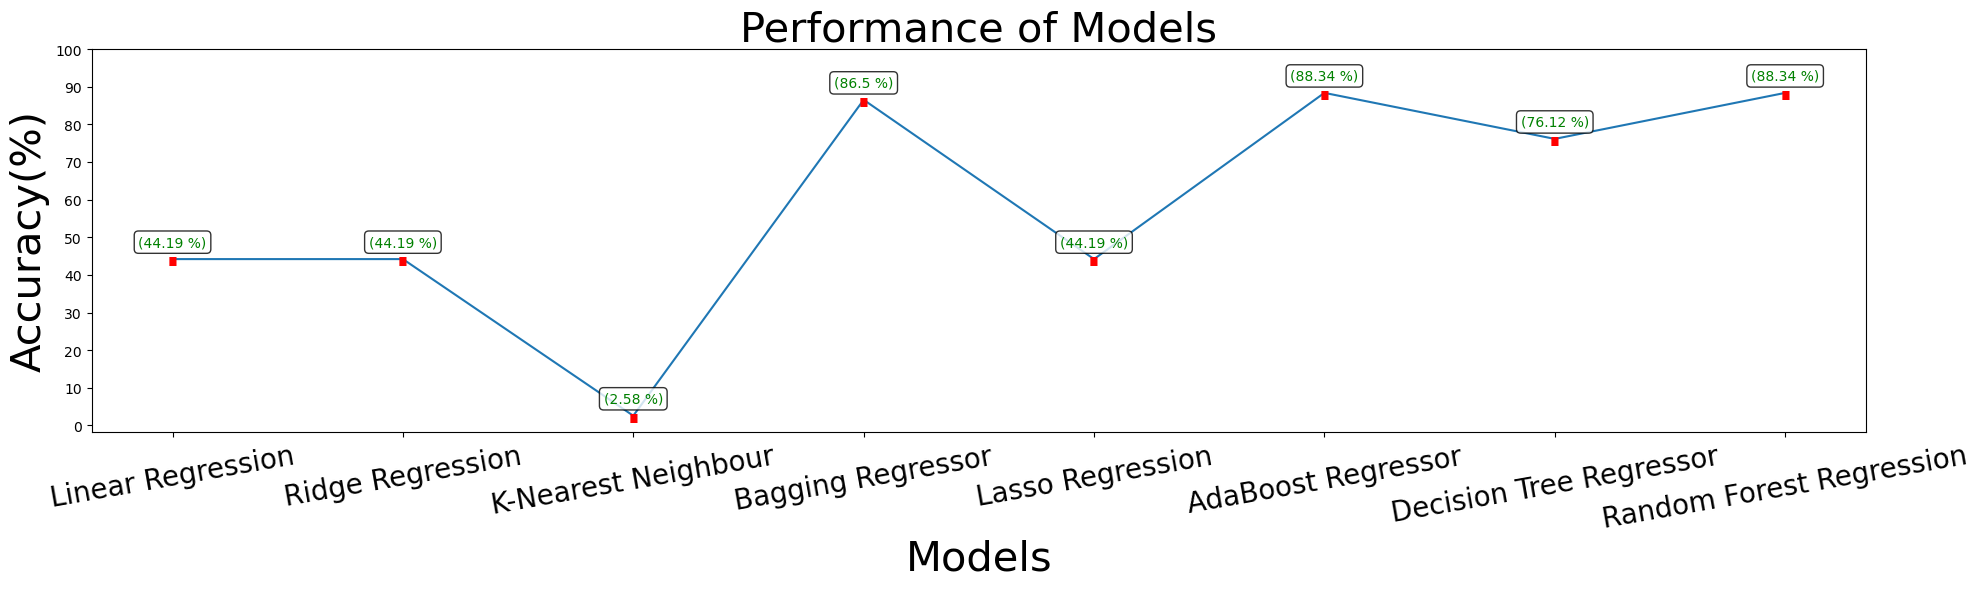

In [57]:
x = list(range(len(model_accuracy)))
y = list(range(0, 101, 10))
props = dict(boxstyle='round', facecolor='white', alpha=0.8)

plt.figure(figsize=(20, 6))

plt.plot(model_accuracy)

plt.yticks(y)
plt.xticks(fontsize=20, rotation=10)
plt.xlabel("Models", fontsize=30)
plt.ylabel("Accuracy(%)", fontsize=30)
plt.title("Performance of Models", fontsize=30)

for a in x:
    b = model_accuracy.iloc[a] 
    
    val = f"({round(b, 2)} %)"
    
    plt.text(a, b + 4.5, val, horizontalalignment='center', verticalalignment='center', color='green', bbox=props)
    plt.text(a, b + 3.5, '.', horizontalalignment='center', verticalalignment='center', color='red', fontsize=50)

plt.tight_layout()
plt.savefig('Overall-Performance.jpg', dpi=600)
plt.show()

In [58]:
testData = pd.read_csv("Test-Set.csv")
testData = testData.loc[:, ~testData.columns.str.contains('Unnamed')]
X_new = testData

In [59]:
drop_columns = ['size', 'condition', 'paint_color', 'posting_date']

X_new = X_new.drop(columns = drop_columns)

In [60]:
manufacturer_map = X_new.dropna(subset=['manufacturer']).set_index('model')['manufacturer'].to_dict()

X_new['manufacturer'] = X_new['manufacturer'].fillna(X_new['model'].map(manufacturer_map))

manufacturer_mode = X_new['manufacturer'].mode()[0]

X_new['manufacturer'].fillna(manufacturer_mode, inplace=True)

In [61]:
X_new['cylinders'] = X_new.groupby('model')['cylinders'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else pd.NA)
)

overall_cylinders_mode = X_new['cylinders'].mode()[0]
X_new['cylinders'].fillna(overall_cylinders_mode, inplace=True)

In [62]:
X_new['drive'] = X_new.groupby('model')['drive'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else pd.NA)
)

drive_mode = X_new['drive'].mode()[0]
X_new['drive'].fillna(drive_mode, inplace=True)

In [63]:
type_map = X_new.dropna(subset=['type']).set_index('model')['type'].to_dict()

X_new['type'] = X_new['type'].fillna(X_new['model'].map(type_map))

type_mode = X_new['type'].mode()[0]
X_new['type'].fillna(type_mode, inplace=True)

In [64]:
fuel_mode = X_new['fuel'].mode()[0]

X_new['fuel'].fillna(fuel_mode, inplace=True)

In [65]:
title_mode = X_new['title_status'].mode()[0]

X_new['title_status'].fillna(title_mode, inplace=True)

In [66]:
X_new['long'] = X_new['long'].fillna(X_new.groupby('state')['long'].transform('mean'))
X_new['lat'] = X_new['lat'].fillna(X_new.groupby('state')['lat'].transform('mean'))

In [67]:
X_new.isna().sum()

id              0
year            0
manufacturer    0
model           0
cylinders       0
fuel            0
odometer        0
title_status    0
transmission    0
drive           0
type            0
state           0
lat             0
long            0
dtype: int64

In [68]:
X_new.reset_index(drop=True, inplace=True)

# Label Processing

In [69]:
label_encoder = preprocessing.LabelEncoder()

In [72]:
X_new[['manufacturer', 'model', 
       'cylinders', 'fuel', 'title_status', 'transmission',
       'drive', 'type',  'state']]=X_new[['manufacturer', 'model',
       'cylinders', 'fuel', 'title_status', 'transmission',
       'drive', 'type', 'state']].apply(label_encoder.fit_transform)

In [ ]:
"""ABR = AdaBoostRegressor(DecisionTreeRegressor(max_depth=24), n_estimators=200, learning_rate=0.1)
ABR.fit(X_train, y_train)

final_predictions = ABR.predict(X_new)
X_new['predicted_price'] = final_predictions
print(X_new[['manufacturer', 'model', 'predicted_price']].head())"""

   manufacturer  model  predicted_price
0            16   4903        -0.902937
1             6   5636         0.385125
2            38  12388        -1.107226
3            29  10756        -0.065074
4             3   3323        -0.134670


In [73]:
ABR = AdaBoostRegressor(
    DecisionTreeRegressor(max_depth=24),
    n_estimators=200,learning_rate=0.1)
ABR.fit(X_train, y_train)
y_pred = ABR.predict(X_test)

In [74]:
y1_pred = ABR.predict(X_new)
X_new

,id,year,manufacturer,model,cylinders,fuel,odometer,title_status,transmission,drive,type,state,lat,long
0,7313399730,2018.0,16,4903,3,2,28898.0,0,0,1,9,37,44.971430,-123.018548
1,7308035814,2017.0,6,5636,5,2,41147.0,0,2,0,9,9,28.040000,-81.960000
2,7317063645,2006.0,38,12388,5,2,165500.0,0,0,1,5,43,32.737108,-97.084585
3,7310376764,2016.0,29,10756,5,4,29430.0,0,2,0,0,48,43.700000,-87.740000
4,7309848062,2017.0,3,3323,5,2,24238.0,0,0,0,9,38,40.790000,-77.850000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124336,7306681704,2015.0,33,1246,5,0,123000.0,0,0,2,8,26,48.202800,-114.303900
124337,7315798680,2007.0,30,10343,5,2,150000.0,4,0,0,9,43,30.242800,-97.765800
124338,7314818147,2015.0,10,5831,3,2,90430.0,0,0,1,9,35,41.563600,-81.573300
124339,7308055654,2001.0,7,814,5,2,137000.0,0,0,0,10,34,42.190134,-78.041382


In [75]:
testData

,id,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,size,type,paint_color,state,lat,long,posting_date
0,7313399730,2018.0,honda,civic,NaN,4 cylinders,gas,28898.0,clean,automatic,fwd,NaN,sedan,NaN,or,44.971430,-123.018548,2021-04-27T10:09:18-0700
1,7308035814,2017.0,cadillac,cts 2.0 luxury sedan 4d,good,NaN,gas,41147.0,clean,other,NaN,NaN,sedan,red,fl,28.040000,-81.960000,2021-04-16T20:21:00-0400
2,7317063645,2006.0,toyota,sienna,excellent,6 cylinders,gas,165500.0,clean,automatic,NaN,NaN,mini-van,grey,tx,32.737108,-97.084585,2021-05-04T20:45:23-0500
3,7310376764,2016.0,mitsubishi,outlander sel sport,good,NaN,other,29430.0,clean,other,NaN,NaN,SUV,white,wi,43.700000,-87.740000,2021-04-21T11:20:50-0500
4,7309848062,2017.0,audi,a6 3.0t premium plus sedan,good,6 cylinders,gas,24238.0,clean,automatic,NaN,NaN,sedan,white,pa,40.790000,-77.850000,2021-04-20T12:10:51-0400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124336,7306681704,2015.0,ram,3500,excellent,6 cylinders,diesel,123000.0,clean,automatic,rwd,NaN,NaN,white,mt,48.202800,-114.303900,2021-04-14T09:29:57-0600
124337,7315798680,2007.0,nissan,murano.awd,NaN,NaN,gas,150000.0,rebuilt,automatic,NaN,NaN,NaN,NaN,tx,30.242800,-97.765800,2021-05-02T11:47:54-0500
124338,7314818147,2015.0,dodge,dart sxt,excellent,4 cylinders,gas,90430.0,clean,automatic,fwd,NaN,NaN,white,oh,41.563600,-81.573300,2021-04-30T11:22:19-0400
124339,7308055654,2001.0,chevrolet,2500,NaN,NaN,gas,137000.0,clean,automatic,NaN,NaN,NaN,NaN,ny,42.190134,-78.041382,2021-04-16T21:15:13-0400


In [76]:
y1_pred

array([-1.29350991,  0.3851246 , -1.06920722, ..., -0.58473003,
       -0.92925176,  0.14267825])

In [ ]:
final_real_prices = scaler.inverse_transform(y1_pred.reshape(-1, 1))

In [79]:
print(final_real_prices)

[[  260.]
 [24500.]
 [ 3499.]
 ...
 [10495.]
 [ 5520.]
 [20999.]]


In [ ]:
price_predict = pd.DataFrame({'id': X_new['id'],'price': final_real_prices.ravel()})

In [82]:
price_predict = price_predict.set_index("id")

In [85]:
price_predict.head(15)

,price
id,
7313399730,260.000000
7308035814,24500.000000
7317063645,3499.000000
7310376764,17990.000000
7309848062,16599.000000
7308652719,23999.000000
7309810883,8800.000000
7315292919,4950.000000
7315244945,4266.438596


In [86]:
price_predict.to_csv("price_predict.csv")